# Using pyCRLD in a distributional framework

## Imports

In [ ]:
#| default_exp DistBase

In [ ]:
#| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
#| export
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial



from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

## Environment for testing

In [ ]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

In [ ]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

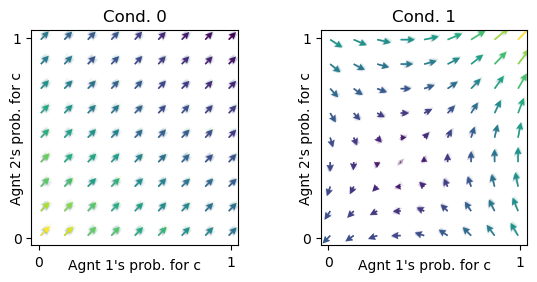

In [ ]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

## A distributional perspective
Discretize rewards into a finate set $\mathcal R = \{r_1, \dots, r_{n_r}\}$


### Discretization grid 

In [ ]:
#| export
def compute_discretization_grid(Rmin, # Minimum reward obtainable
                                Rmax, # Maximum reward obtainable
                                Nr # Number of bin
                                ) -> tuple: # Gridpoints, Width 
    gridpoints = np.linspace(Rmin, Rmax, Nr)
    width  = gridpoints[1] - gridpoints[0]
    return gridpoints, width

We create a regular grid for discretizing the rewards the agent receives,

In [ ]:
gridpoints, width = compute_discretization_grid(env.R.min(), env.R.max(), 8)
gridpoints

array([-4., -3., -2., -1.,  0.,  1.,  2.,  3.])

with

In [ ]:
width

1.0

Illustrating the discretization grid graphically,

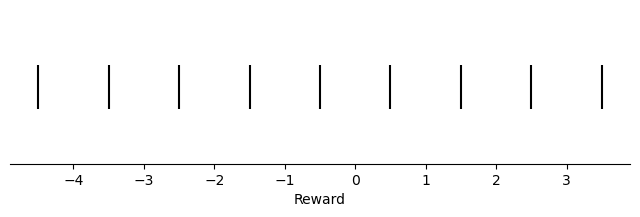

In [ ]:
plt.figure(figsize=(8,2))
plt.gca().spines[['right', 'top', 'left']].set_visible(False)
boundaries = np.array(list(gridpoints - width/2) + 
                      [gridpoints[-1] + width/2])
plt.scatter(boundaries, np.zeros_like(boundaries), marker="|", c='k', s=1000)
plt.yticks([]); plt.xlabel('Reward');

### Reward distribution

We assume (for now) that the environment has a deterministic reward function,
$$R^i(s, \boldsymbol a, s').$$
(Note: This could be extended to deal with environment that have stochastic rewards.)

Next, we transform the reward function into a reward distribution,
$$R^i(s, \boldsymbol a, s', r).$$

In [ ]:
#| export
def compute_Risjasr(env, # The env object
                    nr,  # The number of reward bins
                    discretization_sigma # Width of the discritization normal distribution
                   ) -> np.ndarray: # Reward distribution
    # get the discretization grid
    points, width = compute_discretization_grid(env.R.min(), env.R.max(), nr)

    # init the reward distribution tensor
    Risjasr = np.ones(env.R.shape + (nr,)) * -1  # last dim is distrib
        
    # scale the standard devision with the width of the discritization grid 
    sig = discretization_sigma*width

    # go through the reward tensor of the envrionment
    for index, _ in np.ndenumerate(env.R):
        valr = env.R[index]  # the actual environmental reward value 
        for r in range(nr):
            if r==0: # first interval
                prop = norm.cdf(points[r]+width/2, valr, sig)
            elif r==nr-1: # last interval
                prop = 1 - norm.cdf(points[r]-width/2, valr, sig)
            else: # all other intervals
                prop = norm.cdf(points[r]+width/2, valr, sig)\
                    - norm.cdf(points[r]-width/2, valr, sig)   
            Risjasr[index +(r,)] = prop

    return Risjasr

Testing the reward tensor distribution implementation,

In [ ]:
nr = 21
sig = 0.5
Risjasr = compute_Risjasr(env, nr, sig)
gpoints, wdth = compute_discretization_grid(env.R.min(), env.R.max(), nr)

def plot_Risjasr(i,s,a1,a2,s_, Rr=Risjasr,gpoints=gpoints,wdth=wdth):
    plt.figure(figsize=(8,3))
    plt.gca().spines[['right', 'top', 'left']].set_visible(False)
    plt.bar(gpoints, Rr[i,s,a1,a2,s_,:], width=0.95*wdth, color='k')
    rv = env.R[i,s,a1,a2,s_]
    plt.plot([rv, rv], [0.0, 0.05], c='red', lw=5)
    plt.xlabel("Reward");

For exampe, Agent zero's reward distribution in the prosperous state $s=0$, when both agents cooperate ($a=0$) and the envrionment remains in the prosperous state is 

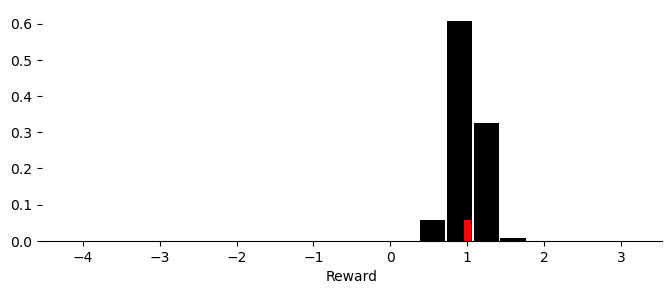

In [ ]:
plot_Risjasr(i=0,s=1,a1=0,a2=0,s_=1)

The red bar indicates the deterministic reward.

If the envrionment collapses, agents are pretty sure to get punsihed for it.

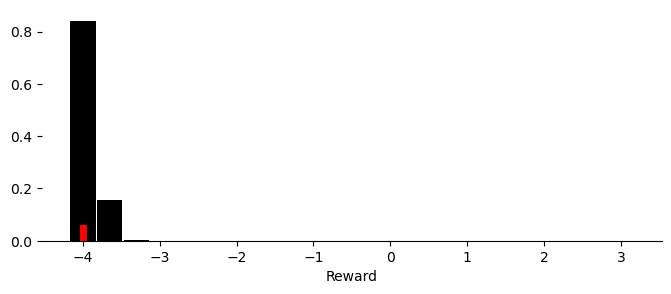

In [ ]:
plot_Risjasr(i=1,s=1,a1=0,a2=1,s_=0)

### Initialize the agent class

In [ ]:
#| export
class distbase(abase):
    """
    Base class for deterministic strategy-average independent (multi-agent)
    temporal-difference reinforcement learning in strategy space.        
    """
    
    def __init__(self,
                 env, # An environment object
                 nr_reward_bins, # The number of bins to resolve rewards
                 discretization_sigma, # standard div for reward discretization
                 learning_rates, # agents' learning rates
                 discount_factors, # agents' discount factors
                 choice_intensities=1.0, # agents' choice intensities
                 opteinsum=True,  # optimize einsum functions
                 **kwargs):

        self.env = env
        Tt = env.T; assert np.allclose(Tt.sum(-1), 1)
        Rt = env.R 
        super().__init__(Tt, Rt, discount_factors, True, opteinsum)
        self.F = jnp.array(env.F)

        # learning rates
        self.alpha = make_variable_vector(learning_rates, self.N)

        # intensity of choice
        self.beta = make_variable_vector(choice_intensities, self.N)
        
        # numer of reward bins
        self.nr = nr_reward_bins
        
        # reward discretization diviation 
        self.discsig = discretization_sigma
        
        # discritization grid
        disc_grid = compute_discretization_grid(env.R.min(), env.R.max(), self.nr)
        self.gridpoints = disc_grid[0]
        self.gridwidth = disc_grid[1]
        
        # reward tensor distrbution
        self.Rr = compute_Risjasr(env, self.nr, self.discsig)


In [ ]:
db = distbase(env,
              nr_reward_bins=8,
              discretization_sigma=0.25,
              learning_rates=0.1,
              discount_factors=0.3)

We define a distributional base agent with `db.nr` bins,

In [ ]:
db.nr

8

In [ ]:
db.discsig

0.25

In [ ]:
db.gridpoints

array([-4., -3., -2., -1.,  0.,  1.,  2.,  3.])

In [ ]:
db.gridwidth

1.0

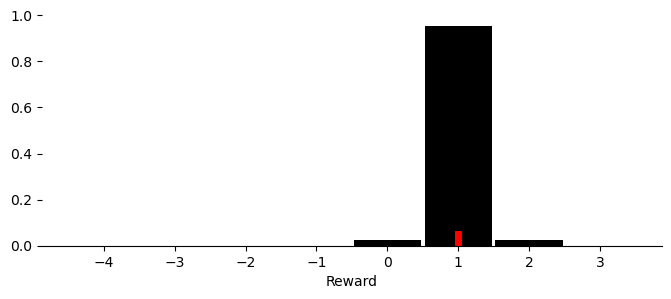

In [ ]:
plot_Risjasr(i=0,s=1,a1=0,a2=0,s_=1,
             Rr=db.Rr, gpoints=db.gridpoints, wdth=db.gridwidth)

### Reward distribution `Risr`

The first *core* method of the distributional RL agent will be `Risr`. This will compute the probability, that agent $i$ receives reward $r$ in state $s$,

$\bar R^i(s, r) = \sum_{s'}\sum_{a^i}\prod_{j} X^j(s, a^j) T(s, \boldsymbol a, s') R^i(s, \boldsymbol a, s', r).$

We will just-in-time (jit) compile this methods with jax.

In [ ]:
#| export
@partial(jit, static_argnums=0)    
def Risr(self:distbase, Xisa):
    i = 0; s = 1; sprim = 2; r=3; b2d = list(range(4, 4+self.N))
    Risjasr = jnp.array(self.Rr)
    
    X4einsum = list(it.chain(*zip(Xisa,
                            [[s, b2d[a]] for a in range(self.N)])))

    args = X4einsum + [env.T, [s]+b2d+[sprim],
                       Risjasr, [i, s]+b2d+[sprim, r], [i, s, r]]

    return jnp.einsum(*args, optimize=self.opti)

distbase.Risr = Risr  # Monkey-patching - possibly problematic?

Note, the monkey-patching example is from [python - fastai.fastcore patch decorator vs simple monkey-patching - Stack Overflow](https://stackoverflow.com/questions/73316102/fastai-fastcore-patch-decorator-vs-simple-monkey-patching). The problem is, that the patch decorator does not work with the `@partial(jit, ...)` decorator.

To compare the performance with jax-free version will also implement a `slow_Risr` method. However, we do so only here for profiling. It won't get exportet to the Python module.

In [ ]:
def slow_Risr(self:distbase, Xisa):
    i = 0; s = 1; sprim = 2; r=3; b2d = list(range(4, 4+self.N))
    Risjasr = np.array(self.Rr)
    
    X4einsum = list(it.chain(*zip(Xisa,
                            [[s, b2d[a]] for a in range(self.N)])))

    args = X4einsum + [env.T, [s]+b2d+[sprim],
                       Risjasr, [i, s]+b2d+[sprim, r], [i, s, r]]

    return np.einsum(*args, optimize=self.opti)

distbase.slow_Risr = slow_Risr  # Monkey-patching - possibly problematic?

Now we test both methods,

In [ ]:
db = distbase(env,
              nr_reward_bins=8,
              discretization_sigma=0.25,
              learning_rates=0.1,
              discount_factors=0.3)

with a random strategy,

In [ ]:
X = jnp.array(mae.random_softmax_strategy())

They should yield the same value,

In [ ]:
np.allclose(db.Risr(X), db.slow_Risr(X))

True

However, their performance is different,

In [ ]:
%timeit db.Risr(X)
%timeit db.slow_Risr(X)

8.3 µs ± 925 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
218 µs ± 4.62 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


Thus, with jit, this method is on this particular machine,

In [ ]:
218/8.3

26.26506024096385

times faster than the jax-free method!

Beyond compute performance, we illustrate the method by a plot,

# TO BE CONTINUED HERE ... 

---

In [ ]:
nbdev.export.nb_export("DistLD.ipynb", "")

Text(0.5, 0, 'Reward value')

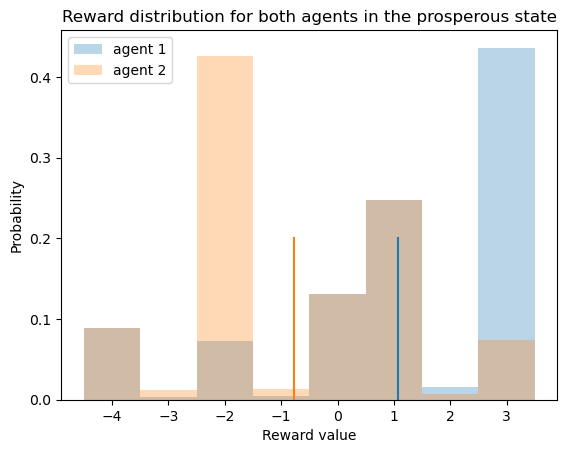

In [ ]:
# Plot reward distrib in the prosperous state


means, delta = db.gridpoints, db.gridwidth
Risr = db.Risr(X)

plt.bar(means, Risr[0,1, :], width=delta, alpha=0.3, label="agent 1")
plt.plot([mae.Ris(X)[0,1],mae.Ris(X)[0,1]],[0, 0.2])

plt.bar(means, Risr[1,1, :], width=delta, alpha=0.3, label="agent 2")
plt.plot([mae.Ris(X)[1,1],mae.Ris(X)[1,1]],[0, 0.2])

plt.legend()

plt.title("Reward distribution for both agents in the prosperous state")
plt.ylabel("Probability")
plt.xlabel("Reward value")

In [ ]:
print("error agent 1 prosperous:", np.dot(means, Risr[0, 1, :]) - mae.Ris(Xisa)[0, 1])
print("error agent 2 prosperous:", np.dot(means, Risr[1, 1, :]) - mae.Ris(Xisa)[1, 1])
print("error agent 1 degraded:", np.dot(means, Risr[0, 0, :]) - mae.Ris(Xisa)[0, 0])
print("error agent 2 degraded:", np.dot(means, Risr[1, 0, :]) - mae.Ris(Xisa)[1, 0])

error agent 1 prosperous: -0.0010389686
error agent 2 prosperous: -0.009468913
error agent 1 degraded: 0.0560019
error agent 2 degraded: 0.0560019


## Return distribution $\bar V^i(s, r)$
For $v, r, v' \in \mathcal R$, 

$$ 
V^i(s, v) =  \sum_{r, v', s'} \delta_{vrv'} R^i(s, r) \bar T(s, s') V^i(s', v')
$$

Summarizing

$$M^i(s, v, s', v') = \sum_r \delta(v, r, v') R^i(s, r) \bar T(s, s') $$

yields

$$ 
V^i(s, v) =  \sum_{v', s'} M^i(s, v, s', v') V^i(s', v').
$$

Now we can combine the indices $s \times v = w$ and have $V^i(w) = \sum_{w'} M(w, w') V^i(w')$ to realize that the return distribution should be found in the eigenvalues of the Bellman matrix $M$.

### Smoothed Bellman Kronecker $\delta_{vrv'}$

In [ ]:
def compute_bellman_ivrv_(mae, n_r, sig=1.0):
    means, delta = compute_means_and_delta(env, n_r)
    sig = sig*delta

    kron_ivrv_ = np.ones((mae.N, n_r, n_r, n_r)) * -1

    for v in range(n_r):
        for r in range(n_r):
            for v_ in range(n_r):
                
                valv_ = 1/mae.gamma * (means[v] - (1-mae.gamma)*means[r])
                
                # gaussian distribution around valq with std `sig` 
                if v_==0:
                    prop = norm.cdf(means[v_]+delta/2, valv_, sig)
                elif v_==n_r-1: # last intervall
                    prop = 1 - norm.cdf(means[v_]-delta/2, valv_, sig)
                else:
                    prop = norm.cdf(means[v_]+delta/2, valv_, sig) - norm.cdf(means[v_]-delta/2, valv_, sig)
                    
                kron_ivrv_[:,v,r,v_] = prop
    return kron_ivrv_
                
b_ivrv_ = compute_bellman_ivrv_(mae, 19)
assert np.allclose(b_ivrv_.sum(-1), 1.0)

In [ ]:
def compute_bellman2_ivrv_(mae, n_r, sig=1.0):
    means, delta = compute_means_and_delta(env, n_r)
    sig = sig*delta

    kron_ivrv_ = np.ones((mae.N, n_r, n_r, n_r)) * -1

    for v in range(n_r):
        for r in range(n_r):
            for v_ in range(n_r):
                
                valv = (1-mae.gamma)*means[r] + mae.gamma*means[v_]
                
                # gaussian distribution around valq with std `sig` 
                if v==0:
                    prop = norm.cdf(means[v]+delta/2, valv, sig)
                elif v==n_r-1: # last intervall
                    prop = 1 - norm.cdf(means[v]-delta/2, valv, sig)
                else:
                    prop = norm.cdf(means[v]+delta/2, valv, sig) - norm.cdf(means[v]-delta/2, valv, sig)
                    
                kron_ivrv_[:,v,r,v_] = prop
    return kron_ivrv_
                
b2_ivrv_ = compute_bellman2_ivrv_(mae, n_r, sig)
assert np.allclose(b2_ivrv_.sum(1), 1.0)

In [ ]:
def compute_doublematrix(mae, Xisa, n_r, sig=0.25):
    Tss = mae.Tss(Xisa)
    Risr = compute_Risr(Xisa, mae.env, n_r, sig)
    b_ivrv_ = compute_bellman_ivrv_(mae, n_r, sig)

    i=0; v=1; r=2; v_=3; s=4; s_=5

    M = np.einsum(b_ivrv_, [i,v,r,v_], Risr, [i, s, r], Tss, [s, s_], [i, s, v, s_, v_])
    np.allclose(M.sum((-2,-1)), 1.0)
    return M

M = compute_doublematrix(mae, Xisa, n_r=16)



NameError: name 'compute_bellman_ivrv_' is not defined

In [ ]:
def compute_doublematrix2(mae, Xisa, n_r, sig=0.25):
    Tss = mae.Tss(Xisa)
    Risr = compute_Risr(Xisa, mae.env, n_r, sig)
    b2_ivrv_ = compute_bellman2_ivrv_(mae, n_r, sig)

    i=0; v=1; r=2; v_=3; s=4; s_=5

    M = np.einsum(b2_ivrv_, [i,v,r,v_], Risr, [i, s, r], Tss, [s, s_], [i, s, v_, s_, v])
    np.allclose(M.sum((-2,-1)), 1.0)
    return M

M = compute_doublematrix2(mae, Xisa, n_r, sig)
np.allclose(M.sum((-2,-1)), 1.0)

True

In [ ]:
def compute_Visr(mae, Xisa, n_r, sig=0.25):
    M = compute_doublematrix(mae, Xisa, n_r, sig)
    Visr = np.ones((mae.N, mae.Z, n_r)) * -1

    for i in range(mae.N):
        mat = M[i].reshape(mae.Z*n_r, mae.Z*n_r)
        _pS = np.array(compute_stationarydistribution(mat))
        _pS = _pS[:, _pS.mean(0)!=-10]
        
        Ps = _pS.reshape(mae.Z, n_r).sum(-1)
        assert np.allclose(mae.Ps(Xisa), Ps, atol=1e-4)

        VIsr = _pS.reshape(mae.Z, n_r) / _pS.reshape(mae.Z, n_r).sum(-1, keepdims=True)

        Visr[i, ...] = VIsr

    return Visr

Visr = compute_Visr(mae, Xisa, n_r, sig)
Visr.sum(-1)

NameError: name 'compute_doublematrix' is not defined

In [ ]:
def compute_Visr2(mae, Xisa, n_r, sig=0.25):
    M = compute_doublematrix2(mae, Xisa, n_r, sig)
    Visr = np.ones((mae.N, mae.Z, n_r)) * -1

    for i in range(mae.N):
        mat = M[i].reshape(mae.Z*n_r, mae.Z*n_r)
        _pS = np.array(compute_stationarydistribution(mat))
        _pS = _pS[:, _pS.mean(0)!=-10]
        
        Ps = _pS.reshape(mae.Z, n_r).sum(-1)
        assert np.allclose(mae.Ps(Xisa), Ps, atol=1e-4)

        VIsr = _pS.reshape(mae.Z, n_r) / _pS.reshape(mae.Z, n_r).sum(-1, keepdims=True)

        Visr[i, ...] = VIsr

    return Visr

Visr = compute_Visr2(mae, Xisa, n_r, sig)
Visr.sum(-1)

array([[1.00000004, 1.00000008],
       [1.00000001, 0.99999992]])

In [ ]:
print("error agent 1 prosperous:", np.dot(means, Visr[0, 1, :]) - mae.Vis(Xisa)[0, 1])
print("error agent 2 prosperous:", np.dot(means, Visr[1, 1, :]) - mae.Vis(Xisa)[1, 1])
print("error agent 1 degraded:", np.dot(means, Visr[0, 0, :]) - mae.Vis(Xisa)[0, 0])
print("error agent 2 degraded:", np.dot(means, Visr[1, 0, :]) - mae.Vis(Xisa)[1, 0])

error agent 1 prosperous: -0.047417045
error agent 2 prosperous: -0.06739153
error agent 1 degraded: 0.23591232
error agent 2 degraded: 0.24417448


Text(0.5, 0, 'Return value')

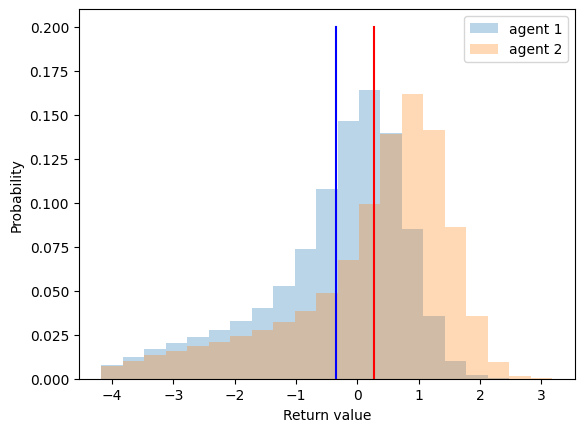

In [ ]:
# n_r = 21; sig=0.25
# means, delta = compute_means_and_delta(env, n_r)
Visr = compute_Visr2(mae, Xisa, n_r, sig)

i, s = 1, 1

plt.bar(means, Visr[0,s, :], width=delta, alpha=0.3, label="agent 1")
plt.bar(means, Visr[i,s, :], width=delta, alpha=0.3, label="agent 2")
plt.plot([mae.Vis(Xisa)[0,s], mae.Vis(Xisa)[0,s]], [0, 0.2], c='b')
plt.plot([mae.Vis(Xisa)[i,s], mae.Vis(Xisa)[i,s]], [0, 0.2], c='r')

plt.legend()
plt.ylabel("Probability")
plt.xlabel("Return value")

# Next value $^{next}V^{i}(s, a, v)$

In [ ]:
# Compute AC-learning's state-action value (distrib):

def compute_nextVisav(mae, Xisa, n_r, sig=sig):
    means, delta = compute_means_and_delta(env, n_r)
    Visr = compute_Visr2(mae, Xisa, n_r, sig)
    
    i = 0; a = 1; s = 2; s_ = 3; r = 4
    j2k = list(range(6, 6+mae.N-1))  # other agents
    b2d = list(range(6+mae.N-1, 6+mae.N-1 + mae.N))  # all actions
    e2f = list(range(5+2*mae.N, 5+2*mae.N + mae.N-1))  # all other acts

    sumsis = [[j2k[l], s, e2f[l]] for l in range(mae.N-1)]  # sum inds
    otherX = list(it.chain(*zip((mae.N-1)*[Xisa], sumsis)))
                                
    args = [mae.Omega, [i]+j2k+[a]+b2d+e2f] + otherX +\
        [env.T, [s]+b2d+[s_], Visr, [i, s_, r], [i, s, a, r]]

    return np.einsum(*args, optimize=mae.opti)

Text(0.5, 0, 'Q value')

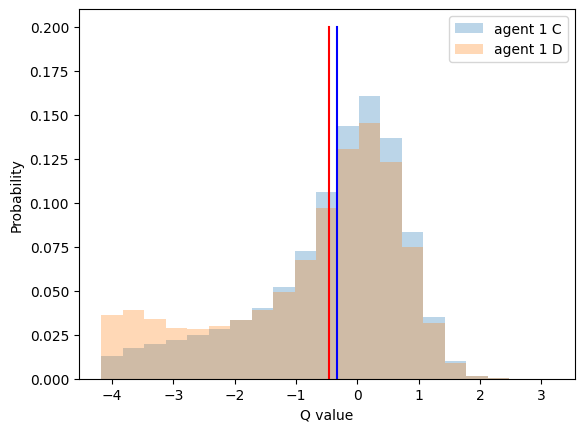

In [ ]:
# n_r = 21; sig=0.25
# means, delta = compute_means_and_delta(env, n_r)
nextVisav = compute_nextVisav(mae, Xisa, n_r, sig)

i, s = 1, 1

plt.bar(means, nextVisav[0,s, 0, :], width=delta, alpha=0.3, label="agent 1 C")
plt.bar(means, nextVisav[0,s, 1, :], width=delta, alpha=0.3, label="agent 1 D")
# plt.bar(means, nextVisav[i,s, 0, :], width=delta, alpha=0.3, label="agent 2")
plt.plot([mae.Qisa(Xisa)[0,1,0], mae.Qisa(Xisa)[0,1,0]], [0, 0.2], c='b')
plt.plot([mae.Qisa(Xisa)[0,1,1], mae.Qisa(Xisa)[0,1,1]], [0, 0.2], c='r')

plt.legend()
plt.ylabel("Probability")
plt.xlabel("Q value")

Text(0.5, 0, 'Q value')

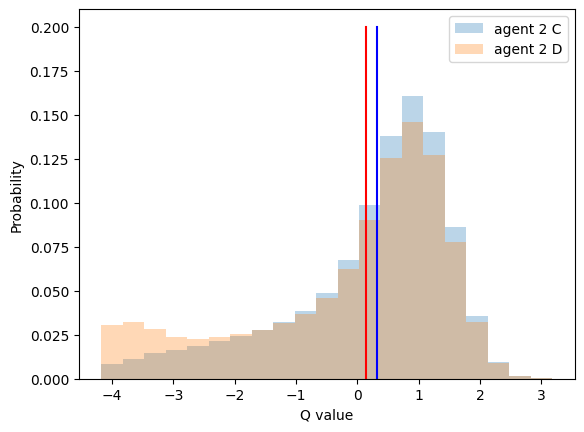

In [ ]:
plt.bar(means, nextVisav[1,s, 0, :], width=delta, alpha=0.3, label="agent 2 C")
plt.bar(means, nextVisav[1,s, 1, :], width=delta, alpha=0.3, label="agent 2 D")
# plt.bar(means, nextVisav[i,s, 0, :], width=delta, alpha=0.3, label="agent 2")
plt.plot([mae.Qisa(Xisa)[1,1,0], mae.Qisa(Xisa)[1,1,0]], [0, 0.2], c='b')
plt.plot([mae.Qisa(Xisa)[1,1,1], mae.Qisa(Xisa)[1,1,1]], [0, 0.2], c='r')

plt.legend()
plt.ylabel("Probability")
plt.xlabel("Q value")

In [ ]:
nextVisav.sum(-1)

array([[[1.00000004, 1.00000004],
        [1.00000011, 1.00000011]],

       [[1.00000001, 1.00000002],
        [0.99999989, 0.9999999 ]]])

In [ ]:
print("error agent 1 prosp coop:", np.dot(means, nextVisav[0, 1, 1, :]) - mae.NextVisa(Xisa)[0, 1, 1])
print("error agent 2 prosp coop:", np.dot(means, nextVisav[1, 1, 1, :]) - mae.NextVisa(Xisa)[1, 1, 1])
print("error agent 1 prosp def:", np.dot(means, nextVisav[0, 1, 0, :]) - mae.NextVisa(Xisa)[0, 1, 0])
print("error agent 2 prosp def:", np.dot(means, nextVisav[1, 1, 0, :]) - mae.NextVisa(Xisa)[1, 1, 0])
print("error agent 1 deg coop:", np.dot(means, nextVisav[0, 0, 1, :]) - mae.NextVisa(Xisa)[0, 0, 1])
print("error agent 2 deg coop:", np.dot(means, nextVisav[1, 0, 1, :]) - mae.NextVisa(Xisa)[1, 0, 1])
print("error agent 1 deg def:", np.dot(means, nextVisav[0, 0, 0, :]) - mae.NextVisa(Xisa)[0, 0, 0])
print("error agent 2 deg def:", np.dot(means, nextVisav[1, 0, 0, :]) - mae.NextVisa(Xisa)[1, 0, 0])

error agent 1 prosp coop: -0.012872279
error agent 2 prosp coop: -0.034543343
error agent 1 prosp def: -0.041205227
error agent 2 prosp def: -0.06569995
error agent 1 deg coop: 0.2286911
error agent 2 deg coop: 0.24329329
error agent 1 deg def: 0.21452451
error agent 2 deg def: 0.22771502


# Prediction error $^{ac}D^{i}(s,a,d)$

In [ ]:
def compute_Risar(mae, Xisa, n_r, sig=sig):
    i = 0; a = 1; s = 2; s_ = 3; r = 4  # Variables
    j2k = list(range(5, 5+mae.N-1))  # other agents
    b2d = list(range(5+mae.N-1, 5+mae.N-1 + mae.N))  # all actions
    e2f = list(range(4+2*mae.N, 4+2*mae.N + mae.N-1))  # all other acts
    Risjasr = compute_Risjasr(env, n_r, sig)
 
    sumsis = [[j2k[l], s, e2f[l]] for l in range(mae.N-1)]  # sum inds
    otherX = list(it.chain(*zip((mae.N-1)*[Xisa], sumsis)))

    args = [mae.Omega, [i]+j2k+[a]+b2d+e2f] + otherX\
        + [mae.T, [s]+b2d+[s_], Risjasr, [i, s]+b2d+[s_, r],
            [i, s, a, r]]
    return np.einsum(*args, optimize=mae.opti)

def compute_Disad(mae, Xisa, n_r, sig=sig):
    # Compute needed tensors
    Risar = compute_Risar(mae, Xisa, n_r, sig)
    Visr = compute_Visr2(mae, Xisa, n_r, sig)
    # Reformat Visr
    Visr_x2 = np.zeros((2, 2, 2, n_r))
    Visr_x2[:, :, 0, :] = Visr
    Visr_x2[:, :, 1, :] = Visr
    nextVisav = compute_nextVisav(mae, Xisa, n_r, sig)
    # define new bins, bounds and means for RPEs
    new_means = np.linspace(means.min() - means.max(), means.max() - means.min(), n_r)
    new_delta = np.unique((new_means[1:] - new_means[:-1]).round(8))
    new_bounds = new_means+new_delta/2
    # new_bounds = np.linspace(np.min(dmat) - new_bin/2, np.max(dmat)+new_bin/2, n_r+1)
    Disad = np.zeros((2, 2, 2, n_r))
    for r in range(n_r):
        for v_ in range(n_r):
            for v in range(n_r):
                # compute possible RPE value
                vald = (1 - mae.gamma[0]) * means[r] + mae.gamma[0] * means[v_] - means[v]
                P_d = Risar[:, :, :, r]*nextVisav[:, :, :, v_]*Visr_x2[:, :, :, v]
                d = int(np.sum(vald>new_bounds))
                Disad[:, :, :, d] += P_d         
    return Disad

In [ ]:
## Attempt with smoothed Bellman Kronecker delta

def compute_bellman_idvrv_(mae, n_r, sig=1.0):
    means, delta = compute_means_and_delta(env, n_r)
    new_means = np.linspace(means.min() - means.max(), means.max() - means.min(), n_r)
    new_delta = np.unique((new_means[1:] - new_means[:-1]).round(8))
    sig = sig*new_delta

    kron_idvrv_ = np.ones((mae.N, n_r, n_r, n_r, n_r)) * -1

    for d in range(n_r):
        for v in range(n_r):
            for r in range(n_r):
                for v_ in range(n_r):
                
                    vald = (1-mae.gamma)*means[r] + mae.gamma*means[v_] - means[v] 
                
                    # gaussian distribution around valq with std `sig` 
                    if d==0:
                        prop = norm.cdf(new_means[d]+new_delta/2, vald, sig)
                    elif d==n_r-1: # last intervall
                        prop = 1 - norm.cdf(new_means[d]-new_delta/2, vald, sig)
                    else:
                        prop = norm.cdf(new_means[d]+new_delta/2, vald, sig) - norm.cdf(new_means[d]-new_delta/2, vald, sig)
                    
                    kron_idvrv_[:,d,v,r,v_] = prop
    return kron_idvrv_
                
b_idvrv_ = compute_bellman_idvrv_(mae, n_r, sig)
assert np.allclose(b_idvrv_.sum(1), 1.0)

In [ ]:
def compute_Disad_kron(mae, Xisa, n_r, sig=sig):
    # Compute needed tensors
    Risar = compute_Risar(mae, Xisa, n_r, sig)
    Visr = compute_Visr2(mae, Xisa, n_r, sig)
    nextVisav = compute_nextVisav(mae, Xisa, n_r, sig)
    # Reformat Visr
    Visr_x2 = np.zeros((2, 2, 2, n_r))
    Visr_x2[:, :, 0, :] = Visr
    Visr_x2[:, :, 1, :] = Visr
    b_idvrv_ = compute_bellman_idvrv_(mae, n_r, sig)

    i=0; d=1; v=2; r=3; v_=4; s=5; a=6; s_=7

    Disad = np.einsum(b_idvrv_, [i,d,v,r,v_], Risar, [i,s,a,r], nextVisav, [i,s,a,v_], 
                      Visr_x2, [i,s,a,v], [i, s, a, d])
    return Disad

In [ ]:
start = datetime.now()
Disad_kron = compute_Disad_kron(mae, Xisa, n_r, sig=sig)
print("duration: "+str(datetime.now()-start))

duration: 0:00:47.741512


In [ ]:
Disad_kron.shape

(2, 2, 2, 21)

In [ ]:
Disad_kron.sum(-1)

array([[[1.00000002, 1.00000003],
        [0.99999985, 0.99999987]],

       [[0.99999984, 0.99999986],
        [0.9999999 , 0.99999989]]])

In [ ]:
start = datetime.now()
Disad = compute_Disad(mae, Xisa, n_r, sig)
print("duration: "+str(datetime.now()-start))

duration: 0:00:11.172074


In [ ]:
Disad.sum(-1)

array([[[1.00000002, 1.00000003],
        [0.99999985, 0.99999987]],

       [[0.99999984, 0.99999986],
        [0.9999999 , 0.99999989]]])

In [ ]:
new_means = np.linspace(means.min() - means.max(), means.max() - means.min(), n_r)
new_delta = np.unique((new_means[1:] - new_means[:-1]).round(8))

Text(0.5, 0, 'Prediction error')

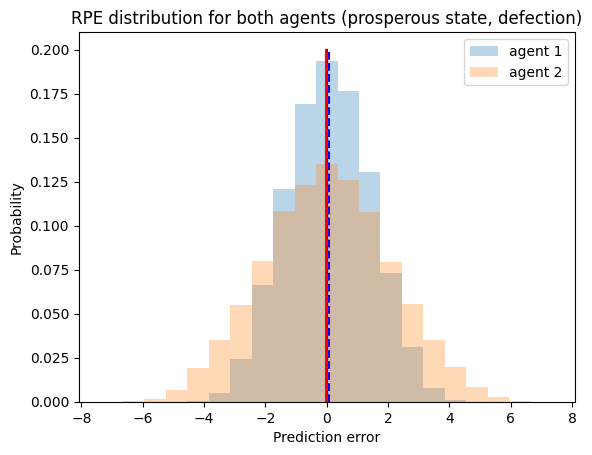

In [ ]:
## Plot pred error distribution

i, s, a = 1, 1, 1

plt.bar(new_means, Disad[0, s, a, :], width=new_delta, alpha=0.3, label="agent 1")
plt.bar(new_means, Disad[1, s, a, :], width=new_delta, alpha=0.3, label="agent 2")
plt.plot([mae.RPEisa(Xisa)[0,s,a], mae.RPEisa(Xisa)[0,s,a]], [0, 0.2], c='b')
plt.plot([np.dot(new_means, Disad[0, s, a, :]), np.dot(new_means, Disad[0, s, a, :])], [0, 0.2], '--', c='b')
plt.plot([mae.RPEisa(Xisa)[1,s,a], mae.RPEisa(Xisa)[1,s,a]], [0, 0.2], c='r')
plt.plot([np.dot(new_means, Disad[1, s, a, :]), np.dot(new_means, Disad[1, s, a, :])], [0, 0.2], '--', c='r')
plt.title("RPE distribution for both agents (prosperous state, defection)")
plt.legend()

plt.ylabel("Probability")
plt.xlabel("Prediction error")

Text(0.5, 0, 'Prediction error')

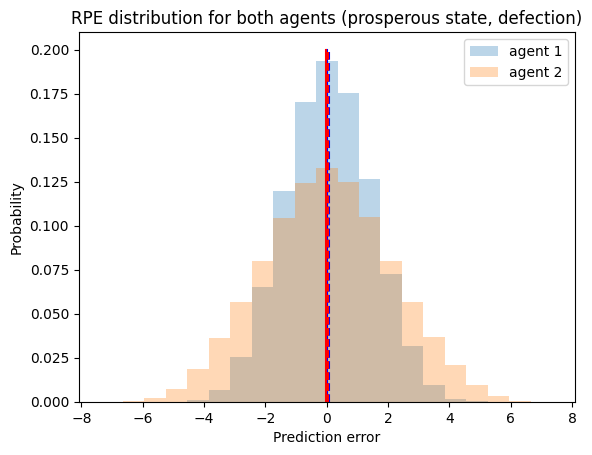

In [ ]:
new_means = np.linspace(means.min() - means.max(), means.max() - means.min(), n_r)
new_delta = np.unique((new_means[1:] - new_means[:-1]).round(8))

## Plot pred error distribution for Disad_kron

i, s, a = 1, 1, 1

plt.bar(new_means, Disad_kron[0, s, a, :], width=new_delta, alpha=0.3, label="agent 1")
plt.bar(new_means, Disad_kron[1, s, a, :], width=new_delta, alpha=0.3, label="agent 2")
plt.plot([mae.RPEisa(Xisa)[0,s,a], mae.RPEisa(Xisa)[0,s,a]], [0, 0.2], c='b')
plt.plot([np.dot(new_means, Disad_kron[0, s, a, :]), np.dot(new_means, Disad_kron[0, s, a, :])], [0, 0.2], '--', c='b')
plt.plot([mae.RPEisa(Xisa)[1,s,a], mae.RPEisa(Xisa)[1,s,a]], [0, 0.2], c='r')
plt.plot([np.dot(new_means, Disad_kron[1, s, a, :]), np.dot(new_means, Disad_kron[1, s, a, :])], [0, 0.2], '--', c='r')
plt.title("RPE distribution for both agents (prosperous state, defection)")
plt.legend()

plt.ylabel("Probability")
plt.xlabel("Prediction error")

In [ ]:
print("error agent 1 prosp def:", np.dot(new_means, Disad[0, 1, 1, :]) - mae.RPEisa(Xisa)[0, 1, 1])
print("error agent 2 prosp def:", np.dot(new_means, Disad[1, 1, 1, :]) - mae.RPEisa(Xisa)[1, 1, 1])
print("error agent 1 prosp coop:", np.dot(new_means, Disad[0, 1, 0, :]) - mae.RPEisa(Xisa)[0, 1, 0])
print("error agent 2 prosp coop:", np.dot(new_means, Disad[1, 1, 0, :]) - mae.RPEisa(Xisa)[1, 1, 0])
print("error agent 1 deg def:", np.dot(new_means, Disad[0, 0, 1, :]) - mae.RPEisa(Xisa)[0, 0, 1])
print("error agent 2 deg def:", np.dot(new_means, Disad[1, 0, 1, :]) - mae.RPEisa(Xisa)[1, 0, 1])
print("error agent 1 deg coop:", np.dot(new_means, Disad[0, 0, 0, :]) - mae.RPEisa(Xisa)[0, 0, 0])
print("error agent 2 deg coop:", np.dot(new_means, Disad[1, 0, 0, :]) - mae.RPEisa(Xisa)[1, 0, 0])

error agent 1 prosp def: 0.04366329
error agent 2 prosp def: 0.039932754
error agent 1 prosp coop: 0.0054007936
error agent 2 prosp coop: 0.016062804
error agent 1 deg def: -0.073207416
error agent 2 deg def: -0.07590203
error agent 1 deg coop: -0.08173489
error agent 2 deg coop: -0.09292268


In [ ]:
print("error agent 1 prosp def:", np.dot(new_means, Disad_kron[0, 1, 1, :]) - mae.RPEisa(Xisa)[0, 1, 1])
print("error agent 2 prosp def:", np.dot(new_means, Disad_kron[1, 1, 1, :]) - mae.RPEisa(Xisa)[1, 1, 1])
print("error agent 1 prosp coop:", np.dot(new_means, Disad_kron[0, 1, 0, :]) - mae.RPEisa(Xisa)[0, 1, 0])
print("error agent 2 prosp coop:", np.dot(new_means, Disad_kron[1, 1, 0, :]) - mae.RPEisa(Xisa)[1, 1, 0])
print("error agent 1 deg def:", np.dot(new_means, Disad_kron[0, 0, 1, :]) - mae.RPEisa(Xisa)[0, 0, 1])
print("error agent 2 deg def:", np.dot(new_means, Disad_kron[1, 0, 1, :]) - mae.RPEisa(Xisa)[1, 0, 1])
print("error agent 1 deg coop:", np.dot(new_means, Disad_kron[0, 0, 0, :]) - mae.RPEisa(Xisa)[0, 0, 0])
print("error agent 2 deg coop:", np.dot(new_means, Disad_kron[1, 0, 0, :]) - mae.RPEisa(Xisa)[1, 0, 0])

error agent 1 prosp def: 0.042301238
error agent 2 prosp def: 0.053700242
error agent 1 prosp coop: 0.020921009
error agent 2 prosp coop: 0.021703385
error agent 1 deg def: -0.022532009
error agent 2 deg def: -0.03264804
error agent 1 deg coop: -0.033831388
error agent 2 deg coop: -0.050439775


In [ ]:
print(np.mean(Disad[0, 1, 1, :]), np.std(Disad[0, 1, 1, :]))

0.047619041299097394 0.06641860404434916


In [ ]:
print(np.mean(Disad_kron[0, 1, 1, :]), np.std(Disad_kron[0, 1, 1, :]))

0.0476190412990973 0.06595588787594896


In [ ]:
print(np.mean(Disad[1, 1, 1, :]), np.std(Disad[1, 1, 1, :]))

0.0476190425462862 0.047461727229613025


In [ ]:
print(np.mean(Disad_kron[1, 1, 1, :]), np.std(Disad_kron[1, 1, 1, :]))

0.04761904254628609 0.04672425692213494
